<a href="https://colab.research.google.com/github/jampsss/Probabilidad-yEstadistica/blob/main/Unidad5/Practica_Unidad_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Análisis del Grupo 1 ---

Descripción Estadística:
       HorasEstudio  Calificacion
count     50.000000      50.00000
mean      14.352000      83.78820
std        4.219174       7.83389
min        3.790000      68.46000
25%       12.032500      78.03500
50%       14.600000      84.49000
75%       17.715000      88.09000
max       20.000000     100.00000


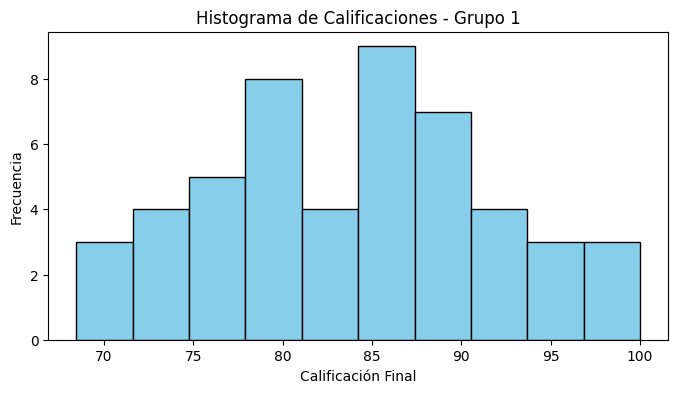


Ecuación de la recta de regresión: y = -0.1061x + 85.3107
Coeficiente de correlación de Pearson (r): -0.0571
Valor p (significancia): 6.9351e-01
Coeficiente de determinación (R^2): 0.0033


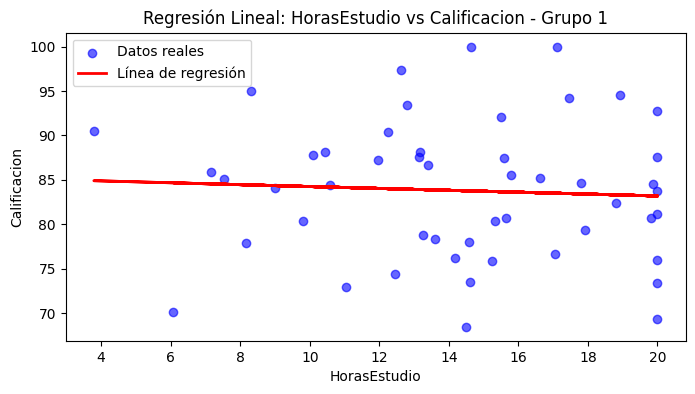



--- Análisis del Grupo 2 ---

Descripción Estadística:
       HorasEstudio  Calificacion
count     50.000000     50.000000
mean      14.352000     75.912000
std        4.219174     20.668922
min        3.790000     26.100000
25%       12.032500     63.500000
50%       14.600000     78.550000
75%       17.715000     93.300000
max       20.000000     99.000000


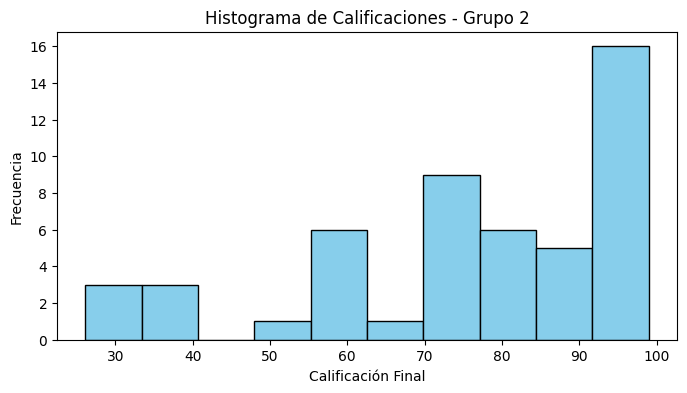


Ecuación de la recta de regresión: y = 4.2227x + 15.3075
Coeficiente de correlación de Pearson (r): 0.8620
Valor p (significancia): 9.0777e-16
Coeficiente de determinación (R^2): 0.7430


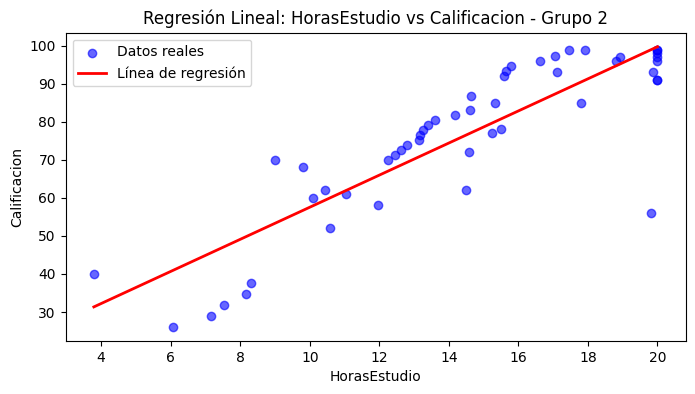



--- Análisis del Grupo 3 ---

Descripción Estadística:
       HorasEstudio  Calificacion
count     50.000000     50.000000
mean      14.352000     75.968000
std        4.219174     23.668867
min        3.790000     15.000000
25%       12.032500     61.000000
50%       14.600000     84.950000
75%       17.715000     94.375000
max       20.000000     99.000000


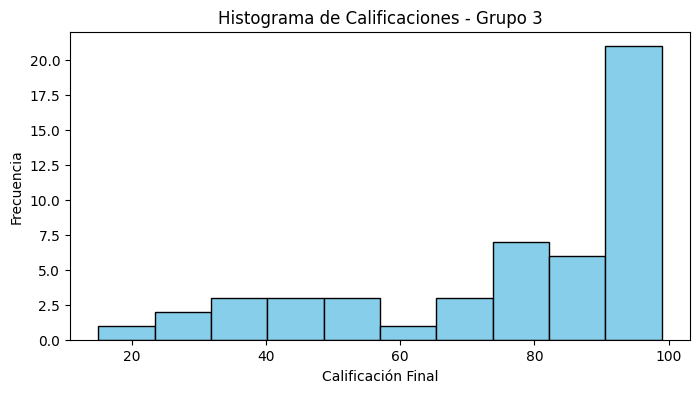


Ecuación de la recta de regresión: y = 5.2857x + 0.1081
Coeficiente de correlación de Pearson (r): 0.9422
Valor p (significancia): 1.9342e-24
Coeficiente de determinación (R^2): 0.8878


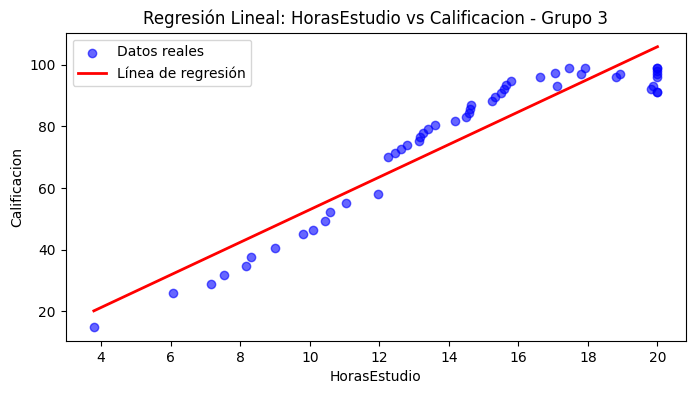

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr

def analizar_grupo(archivo_csv, nombre_grupo):
    print(f"--- Análisis del {nombre_grupo} ---")

    # 1. Carga y Exploración de Datos
    try:
        df = pd.read_csv(archivo_csv)
    except FileNotFoundError:
        print(f"Archivo {archivo_csv} no encontrado.")
        return

    print("\nDescripción Estadística:")
    print(df.describe())


    col_x = 'HorasEstudio'
    col_y = 'Calificacion'

    # Asegurar que no haya valores nulos
    df = df.dropna(subset=[col_x, col_y])

    X = df[[col_x]] # scikit-learn requiere que X sea 2D
    y = df[col_y]

    # 2. Histograma de calificaciones
    plt.figure(figsize=(8, 4))
    plt.hist(y, bins=10, color='skyblue', edgecolor='black')
    plt.title(f'Histograma de Calificaciones - {nombre_grupo}')
    plt.xlabel('Calificación Final')
    plt.ylabel('Frecuencia')
    plt.show()

    # 3. Modelo de Regresión Lineal
    modelo = LinearRegression()
    modelo.fit(X, y)
    pendiente = modelo.coef_[0]
    intercepto = modelo.intercept_

    print(f"\nEcuación de la recta de regresión: y = {pendiente:.4f}x + {intercepto:.4f}")

    # 4. Cálculo de la Correlación
    correlacion, p_value = pearsonr(df[col_x], df[col_y])
    r_cuadrado = modelo.score(X, y)

    print(f"Coeficiente de correlación de Pearson (r): {correlacion:.4f}")
    print(f"Valor p (significancia): {p_value:.4e}")
    print(f"Coeficiente de determinación (R^2): {r_cuadrado:.4f}")

    # 5. Visualización de Resultados
    plt.figure(figsize=(8, 4))
    plt.scatter(X, y, color='blue', alpha=0.6, label='Datos reales')
    plt.plot(X, modelo.predict(X), color='red', linewidth=2, label='Línea de regresión')
    plt.title(f'Regresión Lineal: {col_x} vs {col_y} - {nombre_grupo}')
    plt.xlabel(col_x)
    plt.ylabel(col_y)
    plt.legend()
    plt.show()

    print("\n" + "="*60 + "\n")

# Ejecutar el análisis para los 3 grupos
archivos = ['grupo1.csv', 'grupo2.csv', 'grupo3.csv']
nombres = ['Grupo 1', 'Grupo 2', 'Grupo 3']

for arch, nom in zip(archivos, nombres):
    analizar_grupo(arch, nom)

# Interpretación de Resultados

### Grupo 1

**1. ¿Explicar cuál es la interpretación del coeficiente de regresión en términos de la relación entre el tiempo de estudio y las calificaciones finales?**
El coeficiente de regresión (pendiente) es **-0.1061**. Esto indica que, teóricamente, por cada hora adicional de estudio la calificación final disminuye en 0.1061 puntos. En la práctica, es un valor tan cercano a cero que las horas de estudio no tienen un impacto observable en este grupo.

**2. ¿Cómo se interpreta el coeficiente de correlación en términos de la fuerza y dirección de la relación entre las variables?**
El coeficiente de correlación de Pearson ($r$) es **-0.0571**. Indica una relación inversa, pero **prácticamente nula o muy débil**. Estudiar más no está correlacionado con obtener mejores calificaciones.

**3. ¿El modelo de regresión lineal es estadísticamente significativo?**
**No.** El valor-$p$ (significancia) es de **0.6935**. Al ser mayor al umbral de 0.05, no hay evidencia estadística de una relación real; el patrón observado se debe al azar.

**4. ¿Qué tan confiable es el modelo de regresión para predecir las calificaciones finales de los estudiantes basado en el tiempo de estudio?**
El modelo **no es confiable**. El coeficiente de determinación ($R^2$) es **0.0033**, lo que significa que el tiempo de estudio apenas explica el 0.33% de la variación en las calificaciones.

---

### Grupo 2

**1. ¿Explicar cuál es la interpretación del coeficiente de regresión en términos de la relación entre el tiempo de estudio y las calificaciones finales?**
El coeficiente de regresión (pendiente) es **4.2227**. Por cada hora adicional dedicada al estudio, se espera que la calificación final aumente en promedio 4.22 puntos.

**2. ¿Cómo se interpreta el coeficiente de correlación en términos de la fuerza y dirección de la relación entre las variables?**
El coeficiente de correlación de Pearson ($r$) es **0.8620**. Indica una relación **directa y fuerte**. A más horas de estudio, las calificaciones tienden a subir consistentemente.

**3. ¿El modelo de regresión lineal es estadísticamente significativo?**
**Sí, es altamente significativo.** El valor-$p$ es de **9.07e-16**. Al ser mucho menor que 0.05, podemos afirmar que esta relación positiva no es producto del azar.

**4. ¿Qué tan confiable es el modelo de regresión para predecir las calificaciones finales de los estudiantes basado en el tiempo de estudio?**
El modelo es **bastante confiable**. El coeficiente de determinación ($R^2$) es **0.7430**, indicando que el 74.30% de la variación en las calificaciones se explica por el número de horas de estudio.

---

### Grupo 3

**1. ¿Explicar cuál es la interpretación del coeficiente de regresión en términos de la relación entre el tiempo de estudio y las calificaciones finales?**
El coeficiente de regresión (pendiente) es **5.2857**. Por cada hora adicional de estudio, la calificación final del estudiante aumenta en 5.28 puntos.

**2. ¿Cómo se interpreta el coeficiente de correlación en términos de la fuerza y dirección de la relación entre las variables?**
El coeficiente de correlación de Pearson ($r$) es **0.9422**. Esto representa una relación **directa y sumamente fuerte** (casi perfecta).

**3. ¿El modelo de regresión lineal es estadísticamente significativo?**
**Sí, es extremadamente significativo.** El valor-$p$ es de **1.93e-24**. Al ser un valor prácticamente nulo (menor a 0.05), la probabilidad de que esto sea una coincidencia estadística es nula.

**4. ¿Qué tan confiable es el modelo de regresión para predecir las calificaciones finales de los estudiantes basado en el tiempo de estudio?**
El modelo es **altamente confiable**. El coeficiente de determinación ($R^2$) es **0.8878**, lo que implica que casi el 89% de las variaciones en las calificaciones finales se explican directamente por el tiempo dedicado al estudio.

---

### Conclusiones Generales
El impacto del tiempo de estudio varía significativamente entre los grupos. En el **Grupo 1**, no existe relación entre las horas dedicadas y el rendimiento, lo que sugiere que otros factores (como conocimientos previos, método de estudio o dificultad del examen) determinaron la calificación. En cambio, en los **Grupos 2 y 3**, el estudio constante es el factor determinante para el éxito académico, mostrando relaciones matemáticas robustas donde el Grupo 3 posee la mayor confiabilidad predictiva.